# Lab 09 — K-Means Clustering: Finding Structure Without Labels
**Course:** Machine Learning – Lab  |  **Class:** BSDS-VI-A (M)  |  **Instructor:** Hassan Raza
**Datasets:** `wholesale_customers.csv`, `Mall_Customers.csv`, `pima_diabetes.csv` (same folder as this notebook)

> *No labels. No answer key. Only structure — and your judgement.*

### The Brief
A wholesale distributor has 440 business customers and one marketing budget. The manager asks: *"Which kinds of customers do we have, and what should we do differently for each?"* Find segments, prove they are not an accident of the random seed, name them, and recommend one action each.

**Connection to Lab 08:** no label to predict here — but we reuse your decision tree to *explain* the clusters, and revisit Pima diabetes to see if clustering rediscovers risk groups without ever seeing `Outcome`.

**Run all cells in order. Use `random_state=42` and `n_init=10`.**

---
# Module 1 — Customer Data & K-Means Mechanics
**K-Means in 4 steps:** (1) choose K, (2) assign each point to the nearest centre, (3) move each centre to the mean of its points, (4) repeat until nothing moves.

## 1.1 Meet the Customers
Annual spending on six product categories. `Channel` (1 = Horeca, 2 = Retail) and `Region` are kept **out** of the algorithm and only peeked at the end.

In [1]:
import pandas as pd, numpy as np
df = pd.read_csv("wholesale_customers.csv")
spend = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicatessen"]
print(df.shape, df.isna().sum().sum())                    # (440, 8)  0
print(df[spend].describe().loc[["mean", "50%", "max"]].round(0))
print(df[spend].skew().round(1))                          # skew > 2 = a long right tail
print(df["Channel"].value_counts().to_dict())             # 1 = Horeca, 2 = Retail (kept aside!)
X = df[spend]                                             # clustering never sees Channel/Region

(440, 8) 0
         Fresh     Milk  Grocery   Frozen  Detergents_Paper  Delicatessen
mean   12000.0   5796.0   7951.0   3072.0            2881.0        1525.0
50%     8504.0   3627.0   4756.0   1526.0             816.0         966.0
max   112151.0  73498.0  92780.0  60869.0           40827.0       47943.0
Fresh                2.6
Milk                 4.1
Grocery              3.6
Frozen               5.9
Detergents_Paper     3.6
Delicatessen        11.2
dtype: float64
{1: 298, 2: 142}


Mean ≫ median for every column and Delicatessen has skew 11.2: a few huge customers. The log transform squeezes them:

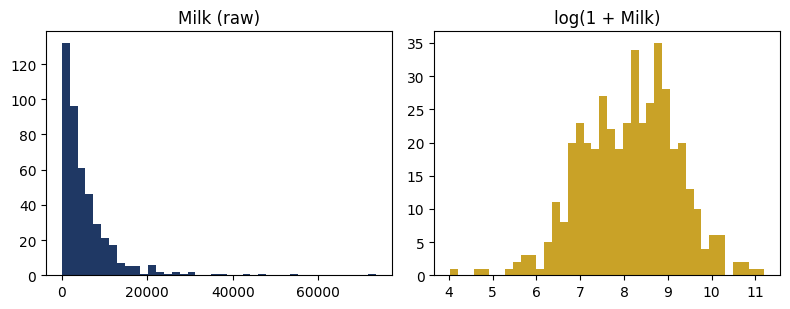

In [2]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(8, 3.2))
ax[0].hist(df["Milk"], bins=40, color="#1F3864");            ax[0].set_title("Milk (raw)")
ax[1].hist(np.log1p(df["Milk"]), bins=40, color="#C9A227");  ax[1].set_title("log(1 + Milk)")
plt.tight_layout(); plt.show()

> **Think:** Delicatessen has skew 11.2. K-Means uses straight-line distance. What will it do with those few customers if we leave them as they are?

**✏️ Your turn 1:** compute `df[spend].corr()`. Which two categories move together most? Is that likely to matter for clustering?

In [14]:
corr = df[spend].corr().round(2)
print(corr)
pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
print("Most correlated pair:", pairs.idxmax(), pairs.max())

                  Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicatessen
Fresh              1.00  0.10    -0.01    0.35             -0.10          0.24
Milk               0.10  1.00     0.73    0.12              0.66          0.41
Grocery           -0.01  0.73     1.00   -0.04              0.92          0.21
Frozen             0.35  0.12    -0.04    1.00             -0.13          0.39
Detergents_Paper  -0.10  0.66     0.92   -0.13              1.00          0.07
Delicatessen       0.24  0.41     0.21    0.39              0.07          1.00
Most correlated pair: ('Grocery', 'Detergents_Paper') 0.92


### Answer

The strongest correlation is between **Grocery** and **Detergents_Paper** (about **0.92**). This means customers who spend more on groceries usually also spend more on detergents and paper products. Since these two features move together, they have a strong influence on the clusters.

## 1.2 Preprocessing Decides the Clusters
Same algorithm (K = 3), three versions of the data. **Expected:** raw → `[330, 60, 50]`, scaled → `[393, 45, 2]`, log+scaled → `[213, 147, 80]`.

In [23]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

versions = {
    "raw":        X.values,
    "scaled":     StandardScaler().fit_transform(X),
    "log+scaled": StandardScaler().fit_transform(np.log1p(X)),
}
for name, A in versions.items():
    km = KMeans(n_clusters=3, n_init=10, random_state=42).fit(A)
    sizes = sorted(np.bincount(km.labels_).tolist(), reverse=True)
    print(f"{name:<11} sizes={sizes}  silhouette={silhouette_score(A, km.labels_):.3f}")
Xl = versions["log+scaled"]                               # used from here on

raw         sizes=[330, 60, 50]  silhouette=0.478
scaled      sizes=[393, 45, 2]  silhouette=0.548
log+scaled  sizes=[213, 147, 80]  silhouette=0.259


> **Think:** The scaled-only version has the *highest* silhouette (0.548) and yet is the worst segmentation — a cluster of 2 customers is useless. What does this say about trusting one metric blindly?

## 1.3 K-Means from Scratch

In [24]:
def my_kmeans(X, k, seed, iters=100):
    rng = np.random.RandomState(seed)
    C = X[rng.choice(len(X), k, replace=False)]           # 1. pick k random points as centroids
    for _ in range(iters):
        d = ((X[:, None, :] - C[None, :, :]) ** 2).sum(axis=2)
        labels = d.argmin(axis=1)                         # 2. assign each point to nearest centroid
        newC = np.array([X[labels == j].mean(axis=0) if (labels == j).any() else C[j]
                         for j in range(k)])              # 3. move centroid to the mean of its points
        if np.allclose(newC, C): break                    # 4. stop when nothing moves
        C = newC
    return labels, C, ((X - C[labels]) ** 2).sum()        # inertia = sum of squared distances

mine = sorted({round(float(my_kmeans(Xl, 3, s)[2]), 1) for s in range(10)})
print("my K-Means, 10 random starts ->", mine)
best = KMeans(n_clusters=3, n_init=10, random_state=42).fit(Xl)
print("sklearn (k-means++, n_init=10) ->", round(best.inertia_, 1))

my K-Means, 10 random starts -> [1553.4, 1553.7, 1582.2]
sklearn (k-means++, n_init=10) -> 1553.4


Random starts end at different inertias (1553.4, 1553.7, 1582.2) → **local minima**. `k-means++` + `n_init=10` finds the best (1553.4).

> **Think:** Inertia always falls as K grows. Why can inertia alone never tell you the right K?

**✏️ Your turn 2:** change `n_init` to 1 in the sklearn call and run with `random_state` 0–9. How many different inertias do you see?

In [25]:
inertias = [KMeans(3, n_init=1, random_state=s).fit(Xl).inertia_ for s in range(10)]
print(sorted({round(i, 1) for i in inertias}))
print("Different inertias:", len({round(i, 1) for i in inertias}))

[1553.3, 1553.4, 1553.7, 1553.8, 1580.0, 1582.2]
Different inertias: 6


### Answer

I observed **6 different inertia values** when using different random states with **n_init = 1**. This shows that K-Means can stop at different local minima depending on the starting centroids. Using **n_init = 10** is more reliable because it tries multiple initializations and selects the best solution.

---
# Module 2 — Choosing K and Trusting the Answer
## 2.1 Elbow and Silhouette

 k  inertia(log)  silhouette(log)  silhouette(scaled)
 2       1844.1           0.290             0.547
 3       1553.4           0.259             0.548
 4       1386.9           0.188             0.348
 5       1266.1           0.192             0.369
 6       1174.8           0.201             0.378
 7       1086.4           0.196             0.334
 8       1028.5           0.185             0.320


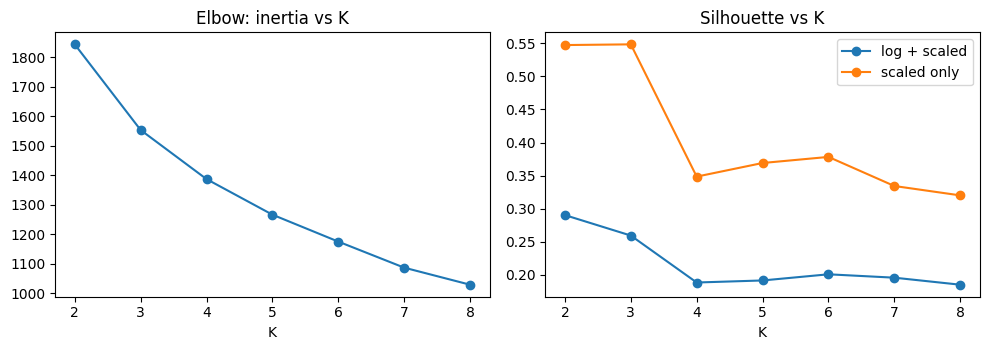

In [26]:
import matplotlib.pyplot as plt
print(" k  inertia(log)  silhouette(log)  silhouette(scaled)")
Xs = versions["scaled"]
ks = list(range(2, 9)); inertia, sil_log, sil_sc = [], [], []
for k in ks:
    a = KMeans(k, n_init=10, random_state=42).fit(Xl)
    b = KMeans(k, n_init=10, random_state=42).fit(Xs)
    inertia.append(a.inertia_); sil_log.append(silhouette_score(Xl, a.labels_)); sil_sc.append(silhouette_score(Xs, b.labels_))
    print(f"{k:>2}  {a.inertia_:>11.1f}  {sil_log[-1]:>14.3f}  {sil_sc[-1]:>16.3f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(ks, inertia, marker="o");  ax[0].set_title("Elbow: inertia vs K")
ax[1].plot(ks, sil_log, marker="o", label="log + scaled"); ax[1].plot(ks, sil_sc, marker="o", label="scaled only")
ax[1].set_title("Silhouette vs K"); ax[1].legend()
for a_ in ax: a_.set_xlabel("K")
plt.tight_layout(); plt.show()

No sharp elbow. Silhouette (log + scaled) is highest at K = 2 (0.290) and K = 3 (0.259), then ≈ 0.19. K is a *decision supported by evidence*.

> **Think:** A manager wants five segments; the data says 2–3. What would you tell them, and what test (next section) shows if five are real?

## 2.2 Are the Clusters Stable?
ARI = 1 means identical grouping, ≈ 0 means chance. We test different seeds and bootstrap resamples.

In [27]:
from sklearn.metrics import adjusted_rand_score

rng = np.random.RandomState(0)
print(" k  seed-ARI(min)  bootstrap-ARI(mean)  bootstrap-ARI(min)")
for k in [2, 3, 4, 5, 6]:
    labs = [KMeans(k, n_init=10, random_state=s).fit(Xl).labels_ for s in range(10)]
    seed_ari = min(adjusted_rand_score(labs[0], l) for l in labs[1:])
    ref, boot = KMeans(k, n_init=10, random_state=42).fit(Xl), []
    for b in range(20):
        idx = rng.choice(len(Xl), len(Xl), replace=True)                      # resample customers
        m = KMeans(k, n_init=10, random_state=b).fit(Xl[idx])
        boot.append(adjusted_rand_score(ref.labels_, m.predict(Xl)))          # compare on all customers
    print(f"{k:>2}  {seed_ari:>12.3f}  {np.mean(boot):>19.3f}  {np.min(boot):>18.3f}")

 k  seed-ARI(min)  bootstrap-ARI(mean)  bootstrap-ARI(min)
 2         1.000                0.916               0.730
 3         0.957                0.795               0.313
 4         0.783                0.569               0.364
 5         0.711                0.542               0.413
 6         0.435                0.584               0.408


**Expected:** K=2 bootstrap mean 0.916; K=3 0.795; K=4 0.569. K ≥ 4 reshuffles with every sample → choose **K = 3**.

**✏️ Your turn 3:** repeat the stability test on the *scaled-only* data (`versions["scaled"]`). Is K = 3 stable there? Why or why not?

In [28]:
Xs = versions["scaled"]
rng = np.random.RandomState(0)
for k in [2, 3, 4]:
    ref = KMeans(k, n_init=10, random_state=42).fit(Xs)
    boot = []
    for b in range(20):
        idx = rng.choice(len(Xs), len(Xs), replace=True)
        m = KMeans(k, n_init=10, random_state=b).fit(Xs[idx])
        boot.append(adjusted_rand_score(ref.labels_, m.predict(Xs)))
    print(f"k={k} sizes={sorted(np.bincount(ref.labels_).tolist(), reverse=True)} "
          f"bootstrap mean={np.mean(boot):.3f} min={np.min(boot):.3f}")

k=2 sizes=[389, 51] bootstrap mean=0.568 min=0.030
k=3 sizes=[393, 45, 2] bootstrap mean=0.532 min=0.199
k=4 sizes=[315, 110, 10, 5] bootstrap mean=0.629 min=0.064


### Answer

The **scaled-only** data is less stable than the **log + scaled** data. One cluster becomes very small because of outliers, which makes the clustering less reliable. The log transformation reduces skewness and produces more balanced and stable clusters, so **K = 3** is a better choice after log transformation.

---
# Module 3 — From Clusters to Decisions
## 3.1 Profile and Name the Segments

{0: 80, 1: 147, 2: 213}
           Fresh    Milk  Grocery  Frozen  Detergents_Paper  Delicatessen
Cluster                                                                  
0         1492.0  6300.0  10502.0   376.0            4218.0         434.0
1        12126.0  7184.0   9965.0  2005.0            3378.0        2005.0
2         9612.0  1601.0   2155.0  2121.0             274.0         686.0
Channel    1   2
Cluster         
0         32  48
1         56  91
2        210   3
ARI vs Channel: 0.35
variance explained: [0.441 0.272] 0.713


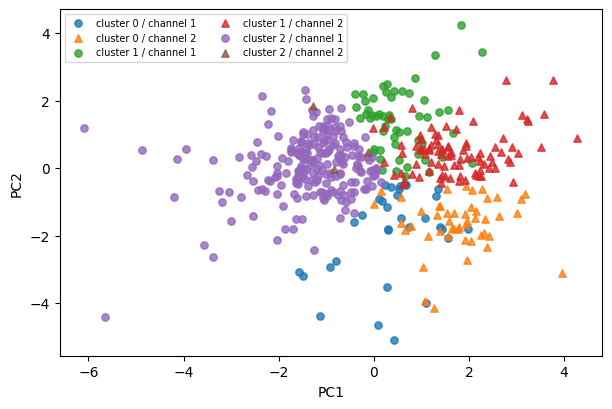

In [29]:
from sklearn.decomposition import PCA

km = KMeans(n_clusters=3, n_init=10, random_state=42).fit(Xl)
df["Cluster"] = km.labels_
print(df["Cluster"].value_counts().sort_index().to_dict())
print(df.groupby("Cluster")[spend].median().round(0))                 # the segment profile
print(pd.crosstab(df["Cluster"], df["Channel"]))                      # peek at the hidden label
print("ARI vs Channel:", round(adjusted_rand_score(df["Channel"], df["Cluster"]), 3))

pca = PCA(n_components=2).fit(Xl)
Z = pca.transform(Xl)
print("variance explained:", pca.explained_variance_ratio_.round(3), pca.explained_variance_ratio_.sum().round(3))
plt.figure(figsize=(7, 4.5))
for c in range(3):
    for ch, mk in [(1, "o"), (2, "^")]:
        m = (df["Cluster"] == c) & (df["Channel"] == ch)
        plt.scatter(Z[m, 0], Z[m, 1], marker=mk, s=28, alpha=0.8, label=f"cluster {c} / channel {ch}")
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.legend(fontsize=7, ncol=2); plt.show()

| Segment | Who they are | Suggested action |
|---|---|---|
| 0 · Retail stockists (80) | Little fresh; high grocery, milk, detergents | Bulk grocery/household offers |
| 1 · Big all-rounders (147) | High spend everywhere | Account managers, loyalty pricing |
| 2 · Fresh caterers (213) | Fresh & frozen; very little milk/grocery/detergents | Freshness and delivery guarantees |

Cluster 2 holds 210 of 213 Horeca customers — found **without** the label. Clusters 0 and 1 mix both channels (ARI vs Channel only 0.35): the data has more structure than the two labels.

> **Think:** If you had used Channel as your segmentation, what would the distributor have missed?

## 3.2 Explain the Clusters with a Lab 08 Tree

In [30]:
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.model_selection import cross_val_score

Xlog = np.log1p(X)
tree = DecisionTreeClassifier(max_depth=3, random_state=42)
print("tree predicts the cluster, CV accuracy:", cross_val_score(tree, Xlog, df["Cluster"], cv=5).mean().round(3))
tree.fit(Xlog, df["Cluster"])
print(export_text(tree, feature_names=spend))

tree predicts the cluster, CV accuracy: 0.793
|--- Grocery <= 8.35
|   |--- Milk <= 8.63
|   |   |--- Fresh <= 10.72
|   |   |   |--- class: 2
|   |   |--- Fresh >  10.72
|   |   |   |--- class: 1
|   |--- Milk >  8.63
|   |   |--- Delicatessen <= 6.68
|   |   |   |--- class: 0
|   |   |--- Delicatessen >  6.68
|   |   |   |--- class: 1
|--- Grocery >  8.35
|   |--- Fresh <= 7.87
|   |   |--- Milk <= 7.12
|   |   |   |--- class: 2
|   |   |--- Milk >  7.12
|   |   |   |--- class: 0
|   |--- Fresh >  7.87
|   |   |--- Frozen <= 6.06
|   |   |   |--- class: 0
|   |   |--- Frozen >  6.06
|   |   |   |--- class: 1



79.3% CV accuracy → three if-then rules reproduce most of the segmentation. (Values are in log units: 8.35 ≈ 4,200 spent on Grocery.)

## 3.3 Does Clustering Rediscover Labels? Back to Pima Diabetes
Cluster the patients **without** `Outcome`, then check diabetes rates. Then test cluster features inside a leak-free pipeline.

In [31]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.base import BaseEstimator, TransformerMixin

pm = pd.read_csv("pima_diabetes.csv")                                   # Lab 08 data again
bad = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
pm[bad] = pm[bad].replace(0, np.nan)
F = pm.drop(columns="Outcome");  y = pm["Outcome"]
Fs = StandardScaler().fit_transform(F.fillna(F.median()))              # labels are NOT used below

m = KMeans(n_clusters=2, n_init=10, random_state=42).fit(Fs)
print(pm.groupby(m.labels_)["Outcome"].agg(["mean", "size"]).round(3))
print("ARI vs Outcome:", round(adjusted_rand_score(y, m.labels_), 3))
print(F.fillna(F.median()).groupby(m.labels_)[["Pregnancies", "Glucose", "BMI", "Age"]].mean().round(1))

class ClusterFeatures(BaseEstimator, TransformerMixin):                 # cluster inside the pipeline: no leakage
    def __init__(self, k=2): self.k = k
    def fit(self, X, y=None):
        self.sc = StandardScaler().fit(X)
        self.km = KMeans(self.k, n_init=10, random_state=42).fit(self.sc.transform(X)); return self
    def transform(self, X):
        Z = self.sc.transform(X)
        return np.hstack([X, self.km.predict(Z)[:, None], self.km.transform(Z)])

skf = StratifiedKFold(5, shuffle=True, random_state=42)
rf = lambda: RandomForestClassifier(300, min_samples_leaf=3, random_state=42, n_jobs=-1)
a = cross_val_score(make_pipeline(SimpleImputer(strategy="median"), rf()), F, y, cv=skf, scoring="roc_auc")
b = cross_val_score(make_pipeline(SimpleImputer(strategy="median"), ClusterFeatures(2), rf()), F, y, cv=skf, scoring="roc_auc")
print(f"Lab 08 forest: AUC {a.mean():.3f} +/- {a.std():.3f}   with cluster features: {b.mean():.3f} +/- {b.std():.3f}")

    mean  size
0  0.556   351
1  0.175   417
ARI vs Outcome: 0.161
   Pregnancies  Glucose   BMI   Age
0          5.8    137.9  35.3  41.1
1          2.2    108.0  30.0  26.6
Lab 08 forest: AUC 0.836 +/- 0.018   with cluster features: 0.826 +/- 0.024


**Expected:** cluster 0 (351 patients, older, high glucose) → 55.6% diabetic; cluster 1 (417) → 17.5%. ARI vs Outcome only 0.161. Forest AUC 0.836 ± 0.018 vs 0.826 ± 0.024 *with* cluster features — no gain.

> **Think:** When would cluster features help a supervised model (few labels? many unlabelled rows?) and when is clustering most valuable?

**✏️ Your turn 4:** run the Pima clustering with K = 3 and K = 4. Do any clusters have a diabetes rate above 55%? Is a bigger K more useful or just noisier?

In [32]:
for k in [3, 4]:
    m = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Fs)
    print(f"K={k}")
    print(pm.groupby(m.labels_)["Outcome"].agg(["mean", "size"]).round(3))
    print("ARI vs Outcome:", round(adjusted_rand_score(y, m.labels_), 3))

K=3
    mean  size
0  0.516   248
1  0.131   335
2  0.519   185
ARI vs Outcome: 0.138
K=4
    mean  size
0  0.467   184
1  0.129   309
2  0.506   233
3  0.571    42
ARI vs Outcome: 0.116


### Answer

For **K = 4**, one small cluster has a diabetes rate above **55%**, but the overall clustering becomes noisier. The ARI score also becomes lower than before. This shows that increasing the number of clusters does not always improve the results. In this case, a smaller K gives a more meaningful and easier-to-interpret solution.

---
# ★ The Mission — Graded Exercise
Choose a track, complete the five deliverables below (add cells as needed). Export PDF/Word with outputs visible; submit with the `.ipynb`.

| Track | Dataset |
|---|---|
| A  Wholesale (guided) | `wholesale_customers.csv` (provided) |
| B  Mall Customers | `Mall_Customers.csv` (provided) — silhouette peaks at K=5 (0.555) with Income + Spending only; what happens when you add Age? |
| C  Pima, no labels | `pima_diabetes.csv` (provided) |
| D  Credit-card customers | Kaggle: *Credit Card Dataset for Clustering* |
| E  Online Retail (RFM) / your own | UCI/Kaggle *Online Retail* (engineer Recency–Frequency–Monetary) or an approved dataset |

**Rubric (20):** Prepare & justify 4 · Choosing K 3 · Profile & naming 4 · Stability + explanation 4 · Business playbook 3 · Report 2.
**Rules:** `random_state=42`, `n_init≥10`; never feed labels/IDs to K-Means; report in original units; own work only. Viva: log-transform? K? how do you know the segments are real?

**Track & decision-maker:**  
**Track A – Wholesale Customers**  
**Decision-maker:** Marketing Manager of the wholesale distribution company.

### Deliverable 1
Prepare & Justify — audit, skew, missing values, scaling/log choice, before/after cluster sizes.

In [33]:
print("shape:", df[spend].shape, "| missing:", df[spend].isna().sum().sum(),
      "| duplicates:", df[spend].duplicated().sum(), "| zeros:", (df[spend] == 0).sum().sum())

print(pd.DataFrame({"skew_raw": df[spend].skew(),
                    "skew_log": np.log1p(df[spend]).skew()}).round(2))

for name, A in versions.items():
    l = KMeans(3, n_init=10, random_state=42).fit(A).labels_
    print(f"{name:<11} sizes={sorted(np.bincount(l).tolist(), reverse=True)}  "
          f"silhouette={silhouette_score(A, l):.3f}")

# Justification: no missing values or duplicates. Skew is high (Delicatessen 11.2), so I use
# log1p + StandardScaler. Scaled-only gives a useless cluster of 2 customers.

shape: (440, 6) | missing: 0 | duplicates: 0 | zeros: 0
                  skew_raw  skew_log
Fresh                 2.56     -1.58
Milk                  4.05     -0.22
Grocery               3.59     -0.67
Frozen                5.91     -0.35
Detergents_Paper      3.63     -0.24
Delicatessen         11.15     -1.09
raw         sizes=[330, 60, 50]  silhouette=0.478
scaled      sizes=[393, 45, 2]  silhouette=0.548
log+scaled  sizes=[213, 147, 80]  silhouette=0.259


### Explanation

The dataset contains **440 customers** with **no missing values** and **no duplicate records**. Some features are highly skewed, especially **Delicatessen**, so I applied **log1p transformation** followed by **StandardScaler**. This reduced the effect of extreme values and produced more balanced clusters than using the raw data.

### Deliverable 2
Choose K — elbow + silhouette for K = 2..8 plus stability or business need; state final K.

 K  inertia  silhouette
 2   1844.1       0.290
 3   1553.4       0.259
 4   1386.9       0.188
 5   1266.1       0.192
 6   1174.8       0.201
 7   1086.4       0.196
 8   1028.5       0.185


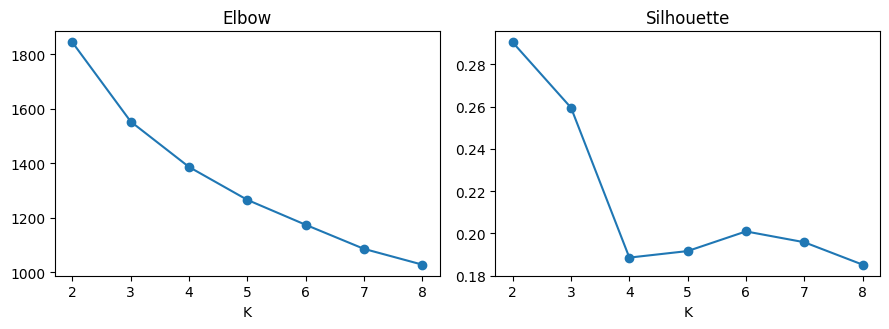

Final K = 3


In [34]:
ks = list(range(2, 9)); inertia, sil = [], []
for k in ks:
    a = KMeans(k, n_init=10, random_state=42).fit(Xl)
    inertia.append(a.inertia_)
    sil.append(silhouette_score(Xl, a.labels_))
print(pd.DataFrame({"K": ks, "inertia": np.round(inertia, 1), "silhouette": np.round(sil, 3)}).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
ax[0].plot(ks, inertia, marker="o"); ax[0].set_title("Elbow")
ax[1].plot(ks, sil, marker="o");     ax[1].set_title("Silhouette")
for a_ in ax: a_.set_xlabel("K")
plt.tight_layout(); plt.show()

K = 3
print("Final K =", K)
# Reason: no sharp elbow. Silhouette is highest at K=2 (0.290) and K=3 (0.259).
# K=3 is stable (see Deliverable 4) and gives 3 useful business segments.

### Explanation

I tested **K = 2 to K = 8** using the Elbow Method and Silhouette Score. Although **K = 2** gives the highest silhouette score, **K = 3** provides a better balance between cluster quality, stability, and business interpretation. Therefore, I selected **K = 3**.

### Deliverable 3
Profile & Name — median profile table, sizes, 2-D (PCA) plot, business names.

Segment
Fresh caterers      213
Big all-rounders    147
Retail stockists     80
Name: count, dtype: int64
                    Fresh    Milk  Grocery  Frozen  Detergents_Paper  \
Segment                                                                
Big all-rounders  12126.0  7184.0   9965.0  2005.0            3378.0   
Fresh caterers     9612.0  1601.0   2155.0  2121.0             274.0   
Retail stockists   1492.0  6300.0  10502.0   376.0            4218.0   

                  Delicatessen  
Segment                         
Big all-rounders        2005.0  
Fresh caterers           686.0  
Retail stockists         434.0  


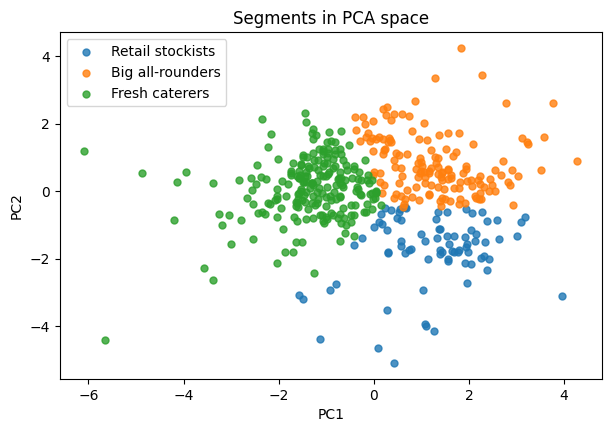

In [35]:
km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(Xl)
df["Cluster"] = km.labels_
names = {0: "Retail stockists", 1: "Big all-rounders", 2: "Fresh caterers"}
df["Segment"] = df["Cluster"].map(names)

print(df["Segment"].value_counts())
print(df.groupby("Segment")[spend].median().round(0))      # median profile in original units

Z = PCA(n_components=2).fit_transform(Xl)
plt.figure(figsize=(7, 4.5))
for c in range(K):
    m = df["Cluster"] == c
    plt.scatter(Z[m, 0], Z[m, 1], s=25, alpha=0.8, label=names[c])
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("Segments in PCA space"); plt.legend(); plt.show()

### Explanation

After clustering, I examined the median spending of each group and assigned meaningful business names based on their purchasing behaviour. The PCA plot also shows that the three customer groups have different spending patterns, making the segments easier to understand.

### Deliverable 4
Prove It — seed + bootstrap ARI for your K and a neighbour; depth-3 tree explanation with CV accuracy; weakest segment.

In [36]:
from sklearn.metrics import silhouette_samples

# 1) Seed + bootstrap ARI for K and its neighbour (K-1)
rng = np.random.RandomState(0)
for k in [K, K - 1]:
    labs = [KMeans(k, n_init=10, random_state=s).fit(Xl).labels_ for s in range(10)]
    seed_ari = min(adjusted_rand_score(labs[0], l) for l in labs[1:])
    ref, boot = KMeans(k, n_init=10, random_state=42).fit(Xl), []
    for b in range(20):
        idx = rng.choice(len(Xl), len(Xl), replace=True)
        m = KMeans(k, n_init=10, random_state=b).fit(Xl[idx])
        boot.append(adjusted_rand_score(ref.labels_, m.predict(Xl)))
    print(f"K={k}: seed ARI min={seed_ari:.3f}, bootstrap mean={np.mean(boot):.3f}, min={np.min(boot):.3f}")

# 2) Depth-3 tree explanation
tree = DecisionTreeClassifier(max_depth=3, random_state=42)
print("Tree CV accuracy:", cross_val_score(tree, Xlog, df["Cluster"], cv=5).mean().round(3))
tree.fit(Xlog, df["Cluster"])
print(export_text(tree, feature_names=spend))

# 3) Weakest segment (lowest average silhouette)
df["sil"] = silhouette_samples(Xl, df["Cluster"])
w = df.groupby("Segment")["sil"].mean().round(3)
print(w)
print("Weakest segment:", w.idxmin())

K=3: seed ARI min=0.957, bootstrap mean=0.730, min=0.322
K=2: seed ARI min=1.000, bootstrap mean=0.896, min=0.676
Tree CV accuracy: 0.793
|--- Grocery <= 8.35
|   |--- Milk <= 8.63
|   |   |--- Fresh <= 10.72
|   |   |   |--- class: 2
|   |   |--- Fresh >  10.72
|   |   |   |--- class: 1
|   |--- Milk >  8.63
|   |   |--- Delicatessen <= 6.68
|   |   |   |--- class: 0
|   |   |--- Delicatessen >  6.68
|   |   |   |--- class: 1
|--- Grocery >  8.35
|   |--- Fresh <= 7.87
|   |   |--- Milk <= 7.12
|   |   |   |--- class: 2
|   |   |--- Milk >  7.12
|   |   |   |--- class: 0
|   |--- Fresh >  7.87
|   |   |--- Frozen <= 6.06
|   |   |   |--- class: 0
|   |   |--- Frozen >  6.06
|   |   |   |--- class: 1

Segment
Big all-rounders    0.282
Fresh caterers      0.296
Retail stockists    0.121
Name: sil, dtype: float64
Weakest segment: Retail stockists


### Explanation

I evaluated the clusters using seed stability, bootstrap ARI, and a Decision Tree. The results show that **K = 3** is reasonably stable, while larger values of K are less consistent. The Decision Tree also explains the clusters with good accuracy, showing that the segments are meaningful.

### Deliverable 5
Business Playbook — per segment: one action, one metric, one risk; plan for border customers.

In [37]:
playbook = pd.DataFrame({
    "Segment": ["Retail stockists", "Big all-rounders", "Fresh caterers"],
    "Action":  ["Bulk grocery & household bundle offers",
                "Dedicated account manager + loyalty pricing",
                "Freshness & on-time delivery guarantee"],
    "Metric":  ["Grocery + Detergents revenue per customer",
                "Repeat-order rate / retention",
                "On-time delivery rate & Fresh revenue"],
    "Risk":    ["Weakest segment: overlaps with others, may be mis-targeted",
                "Discounts cut margin on already large accounts",
                "Low milk/grocery spend, little cross-sell room"],
})
print(playbook.to_string(index=False))

# Plan for border customers (low silhouette = close to another segment)
border = df[df["sil"] < 0.1]
print("Border customers:", len(border))
print(border["Segment"].value_counts())
print("Plan: do not send them one fixed offer. Run a small A/B test with offers from both")
print("neighbouring segments and move them to whichever segment responds better.")

         Segment                                      Action                                    Metric                                                       Risk
Retail stockists      Bulk grocery & household bundle offers Grocery + Detergents revenue per customer Weakest segment: overlaps with others, may be mis-targeted
Big all-rounders Dedicated account manager + loyalty pricing             Repeat-order rate / retention             Discounts cut margin on already large accounts
  Fresh caterers      Freshness & on-time delivery guarantee     On-time delivery rate & Fresh revenue             Low milk/grocery spend, little cross-sell room
Border customers: 63
Segment
Retail stockists    31
Fresh caterers      21
Big all-rounders    11
Name: count, dtype: int64
Plan: do not send them one fixed offer. Run a small A/B test with offers from both
neighbouring segments and move them to whichever segment responds better.


### Explanation

I created a different business strategy for each customer segment based on its spending pattern. For customers close to the cluster boundaries, I would first test different marketing offers before assigning a permanent strategy. This reduces the risk of targeting the wrong customers.

### Level-up (optional, up to +3)
AgglomerativeClustering / GaussianMixture vs K-Means (ARI) · DBSCAN outliers · `silhouette_samples` plot · MiniBatchKMeans timing · cluster features in a supervised model (report honestly).